# Redes nueronales (cuerpo del proyecto)

## Set up

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import load_config
from src.runtime import limit_threads
cfg = load_config()
N_THREADS = limit_threads(cfg)                      # ANTES de usar Keras

import keras
from src.preprocessing import load_split
from src.models import build_model
from src.train import make_inputs, train_model

SEED = cfg["seeds"][0]
tr, dv = load_split(cfg, "train"), load_split(cfg, "dev")
X_tr, idx_tr, y_tr = tr["X"], tr["idx"], tr["y"]["isFraud"]
X_dv, idx_dv, y_dv = dv["X"], dv["idx"], dv["y"]["isFraud"]

meta = json.load(open(ROOT / cfg["paths"]["models_dir"] / "preprocessor_meta.json"))
vocab, idx_cols = meta["vocab_sizes"], list(meta["vocab_sizes"])
idx_tr, idx_dv = idx_tr[idx_cols], idx_dv[idx_cols]
for c, v in vocab.items():                          # ningún índice fuera del vocabulario
    assert 0 <= idx_tr[c].min() and idx_tr[c].max() < v and idx_dv[c].max() < v, c
print("entradas OK:", X_tr.shape, len(idx_cols), "columnas idx")

entradas OK: (413378, 383) 13 columnas idx


## Exploración básica de funcionamiento

### Prueba de humo para el entrenamiento

In [2]:
for kind, strat in [("mlp", "class_weight"), ("mlp_regularizado", "class_weight"),
                    ("mlp_embeddings", "class_weight"), ("residual_mlp", "class_weight"),
                    ("mlp", "focal")]:
    keras.backend.clear_session()
    model = build_model(kind, cfg, X_tr.shape[1], vocab)
    tr_in = make_inputs(X_tr, idx_tr, kind, idx_cols)
    dv_in = make_inputs(X_dv, idx_dv, kind, idx_cols)
    out = train_model(model, (tr_in, y_tr), (dv_in, y_dv), cfg, strat, SEED, kind=kind,
                      variant="smoke", n_features=X_tr.shape[1], max_epochs=3,
                      log=False, save_weights=False)
    h = out["history"]["val_pr_auc"]
    print(f"{kind:<18} {strat:<13} {model.count_params():>9,} params | "
          f"val_pr_auc por época {np.round(h, 3)} | {out['train_time_s']/len(h):.1f} s/época")


mlp                class_weight    131,329 params | val_pr_auc por época [0.451 0.467 0.465] | 1.3 s/época
mlp_regularizado   class_weight    132,481 params | val_pr_auc por época [0.436 0.46  0.467] | 1.9 s/época
mlp_embeddings     class_weight    255,330 params | val_pr_auc por época [0.466 0.484 0.494] | 3.4 s/época
residual_mlp       class_weight    498,689 params | val_pr_auc por época [0.41  0.446 0.468] | 6.1 s/época
mlp                focal           131,329 params | val_pr_auc por época [0.436 0.464 0.476] | 1.3 s/época


### Resumen ejecutivo de las NN

RESUMEN COMPARATIVO


,Arquitectura,Entradas,Dense,BatchNorm,Dropout,Embedding,Add (residual),Entrenables,No entrenables (BN),Total,MB (float32)
0,1. MLP convencional,1,3,0,0,0,0,131329,0,131329,0.53
1,2. MLP regularizada,1,3,2,2,0,0,131713,768,132481,0.53
2,3. MLP con embeddings,14,3,2,2,13,0,254562,768,255330,1.02
3,4. Residual MLP,1,8,7,3,0,3,495105,3584,498689,1.99



HIPERPARÁMETROS DE LA CONFIGURACIÓN


,Arquitectura,Hiperparámetros
0,1. MLP convencional,"{""hidden"": [256, 128]}"
1,2. MLP regularizada,"{""hidden"": [256, 128], ""dropout"": 0.3, ""l2"": 1..."
2,3. MLP con embeddings,"{""hidden"": [256, 128], ""dropout"": 0.3, ""l2"": 1..."
3,4. Residual MLP,"{""width"": 256, ""n_blocks"": 3, ""dropout"": 0.2, ..."



PROTOCOLO DE ENTRENAMIENTO


,Elemento,Valor
0,Datos de entrada,X: 383 columnas; idx: 13 columnas de índices (...
1,Filas,"train 413,378 | dev 88,581 (el test no se usa ..."
2,Optimizador,"Adam, tasa de aprendizaje 0.001"
3,Tamaño de lote / épocas máximas,2048 / 100
4,Early stopping,"PR-AUC exacto en dev, paciencia 10, restore_be..."
5,Inicialización,He normal en las capas Dense; Embedding con la...
6,Estrategia class_weight,entropía cruzada binaria con pesos de train 0....
7,Estrategia focal,"BinaryFocalCrossentropy (gamma=2.0, alpha=None..."
8,Costo asumido,"c_FN=10, c_FP=1, precisión objetivo 0.5"
9,Semillas,"[19, 69, 79] (búsqueda con 19)"


... (7 outputs left out)

,#,Capa,Tipo,Salida,Parámetros,Detalle
0,0,card1_idx,InputLayer,"(1,)",0,
1,1,card2_idx,InputLayer,"(1,)",0,
2,2,card3_idx,InputLayer,"(1,)",0,
3,3,card5_idx,InputLayer,"(1,)",0,
4,4,addr1_idx,InputLayer,"(1,)",0,
5,5,addr2_idx,InputLayer,"(1,)",0,
6,6,P_emaildomain_idx,InputLayer,"(1,)",0,
7,7,R_emaildomain_idx,InputLayer,"(1,)",0,
8,8,id_30_idx,InputLayer,"(1,)",0,
9,9,id_31_idx,InputLayer,"(1,)",0,


Model: "mlp_embeddings"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                 ┃           Param # ┃ Connected to              
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━
│ card1_idx (InputLayer)            │ (None, 1)                    │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ card2_idx (InputLayer)            │ (None, 1)                    │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ card3_idx (InputLayer)            │ (None, 1)                    │                 0 │ -                         
├───────────────────────────────────┼───────────

,#,Capa,Tipo,Salida,Parámetros,Detalle
0,0,x,InputLayer,"(383,)",0,
1,1,dense,Dense,"(256,)",98048,"unidades=256, activación=linear, sesgo=False, ..."
2,2,batch_normalization,BatchNormalization,"(256,)",1024,"momentum=0.99, épsilon=0.001"
3,3,activation,Activation,"(256,)",0,activación=relu
4,4,dense_1,Dense,"(256,)",65536,"unidades=256, activación=linear, sesgo=False, ..."
5,5,batch_normalization_1,BatchNormalization,"(256,)",1024,"momentum=0.99, épsilon=0.001"
6,6,activation_1,Activation,"(256,)",0,activación=relu
7,7,dropout,Dropout,"(256,)",0,tasa=0.2
8,8,dense_2,Dense,"(256,)",65536,"unidades=256, activación=linear, sesgo=False, ..."
9,9,batch_normalization_2,BatchNormalization,"(256,)",1024,"momentum=0.99, épsilon=0.001"


Model: "residual_mlp"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                 ┃           Param # ┃ Connected to              
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━
│ x (InputLayer)                    │ (None, 383)                  │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ dense (Dense)                     │ (None, 256)                  │            98,048 │ x[0][0]                   
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ batch_normalization               │ (None, 256)                  │             1,024 │ dense[0][0]               
│ (BatchNormalization)              │             

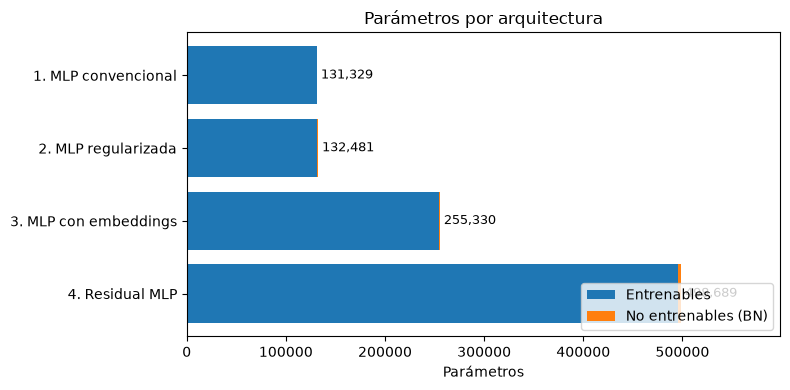


Guardado: reports\nn_architectures.md | CSV por arquitectura en reports/ | figura 23_nn_parameters.png


In [3]:
# ============================================================
# Documentación de las arquitecturas (parámetros e información de las redes)
# ===========================================================

import io
import keras
from collections import Counter
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from src.train import compute_class_weights



KINDS = ["mlp", "mlp_regularizado", "mlp_embeddings", "residual_mlp"]
NOMBRES = {"mlp": "1. MLP convencional", "mlp_regularizado": "2. MLP regularizada",
           "mlp_embeddings": "3. MLP con embeddings", "residual_mlp": "4. Residual MLP"}
OVERRIDES = {}     # tras la Acción 8: {"mlp_regularizado": {"hidden": [512, 256], "dropout": 0.2}, ...}
HACER_DIAGRAMAS = True   # requiere pydot + Graphviz; si faltan, se omite sin error

FIG_DIR = ROOT / cfg["paths"]["figures_dir"]
OUT_MD = ROOT / "reports" / "nn_architectures.md"
OUT_MD.parent.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _clase(x):
    return x.get("class_name", "") if isinstance(x, dict) else (x or "")

def _l2(x):
    if isinstance(x, dict) and str(x.get("class_name", "")).lower() == "l2":
        return x["config"].get("l2")
    return None

def forma(layer):
    try:
        return str(tuple(layer.output.shape[1:]))
    except Exception:
        return "?"

def detalle(layer):
    c, t = layer.get_config(), layer.__class__.__name__
    if t == "Dense":
        s = (f"unidades={c['units']}, activación={c['activation']}, sesgo={c['use_bias']}, "
             f"inicialización={_clase(c['kernel_initializer'])}")
        l2 = _l2(c.get("kernel_regularizer"))
        return s + (f", L2={l2:g}" if l2 else "")
    if t == "BatchNormalization":
        return f"momentum={c['momentum']}, épsilon={c['epsilon']}"
    if t == "Dropout":
        return f"tasa={c['rate']}"
    if t == "Embedding":
        s = f"vocabulario={c['input_dim']}, dimensión={c['output_dim']}"
        l2 = _l2(c.get("embeddings_regularizer"))
        return s + (f", L2={l2:g}" if l2 else "")
    if t == "Activation":
        return f"activación={c['activation']}"
    return ""

def md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(str(v).replace("|", "\\|") for v in r) + " |")
    return "\n".join(out)


resumen, capas, resumenes_keras, emb_tabla, hp_rows = [], {}, {}, None, []
for kind in KINDS:
    keras.backend.clear_session()
    m = build_model(kind, cfg, X_tr.shape[1], vocab, **OVERRIDES.get(kind, {}))

    # parámetros
    n_tr = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    n_nt = int(sum(np.prod(w.shape) for w in m.non_trainable_weights))
    cnt = Counter(l.__class__.__name__ for l in m.layers)
    hp = {**cfg["nn"]["architectures"][kind], **OVERRIDES.get(kind, {})}
    resumen.append({
        "Arquitectura": NOMBRES[kind], "Entradas": len(m.inputs),
        "Dense": cnt["Dense"], "BatchNorm": cnt["BatchNormalization"], "Dropout": cnt["Dropout"],
        "Embedding": cnt["Embedding"], "Add (residual)": cnt["Add"],
        "Entrenables": n_tr, "No entrenables (BN)": n_nt, "Total": n_tr + n_nt,
        "MB (float32)": round((n_tr + n_nt) * 4 / 1e6, 2),
    })
    hp_rows.append({"Arquitectura": NOMBRES[kind], "Hiperparámetros": json.dumps(hp)})

    # capa por capa
    capas[kind] = pd.DataFrame([{
        "#": i, "Capa": l.name, "Tipo": l.__class__.__name__, "Salida": forma(l),
        "Parámetros": l.count_params(), "Detalle": detalle(l)} for i, l in enumerate(m.layers)])
    capas[kind].to_csv(ROOT / "reports" / f"nn_layers_{kind}.csv", index=False)

    # summary de Keras como texto
    lineas = []
    m.summary(print_fn=lambda s, **k: lineas.append(str(s)), line_length=120)
    resumenes_keras[kind] = "\n".join(lineas)

    # tabla de embeddings
    if kind == "mlp_embeddings":
        filas = []
        for l in m.layers:
            if l.__class__.__name__ == "Embedding":
                c = l.get_config()
                filas.append({"Variable": l.name.replace("emb_", ""), "Vocabulario": c["input_dim"],
                              "Dimensión": c["output_dim"], "Parámetros": l.count_params()})
        emb_tabla = pd.DataFrame(filas)
        emb_tabla["% de los parámetros de embeddings"] = (100 * emb_tabla["Parámetros"]
                                                          / emb_tabla["Parámetros"].sum()).round(1)

    if HACER_DIAGRAMAS:
        try:
            keras.utils.plot_model(m, to_file=str(FIG_DIR / f"arch_{kind}.png"),
                                   show_shapes=True, show_layer_names=True, dpi=110)
        except Exception as e:
            HACER_DIAGRAMAS = False
            print("Diagramas omitidos (requieren pydot y Graphviz):", type(e).__name__)

resumen_df, hp_df = pd.DataFrame(resumen), pd.DataFrame(hp_rows)

# protocolo de entrenamiento
w = compute_class_weights(y_tr, cfg["imbalance"]["class_weight_mode"])
nn_c, imb = cfg["nn"]["common"], cfg["imbalance"]
protocolo = pd.DataFrame([
    ("Datos de entrada", f"X: {X_tr.shape[1]} columnas; idx: {len(vocab)} columnas de índices (solo la MLP con embeddings)"),
    ("Filas", f"train {len(X_tr):,} | dev {len(X_dv):,} (el test no se usa en esta etapa)"),
    ("Optimizador", f"Adam, tasa de aprendizaje {nn_c['learning_rate']}"),
    ("Tamaño de lote / épocas máximas", f"{nn_c['batch_size']} / {nn_c['max_epochs']}"),
    ("Early stopping", f"PR-AUC exacto en dev, paciencia {nn_c['early_stopping_patience']}, restore_best_weights=True"),
    ("Inicialización", "He normal en las capas Dense; Embedding con la inicialización por defecto de Keras"),
    ("Estrategia class_weight", f"entropía cruzada binaria con pesos de train {w['class_weight'][0]:.3f} / "
                                f"{w['class_weight'][1]:.3f}; sesgo de salida inicial 0"),
    ("Estrategia focal", f"BinaryFocalCrossentropy (gamma={imb['focal_gamma']}, alpha={imb['focal_alpha']}), sin pesos "
                         f"de clase; sesgo de salida inicial log(n1/n0) = {np.log(w['n1'] / w['n0']):.3f}"),
    ("Costo asumido", f"c_FN={cfg['cost']['c_FN']}, c_FP={cfg['cost']['c_FP']}, precisión objetivo {cfg['cost']['target_precision']}"),
    ("Semillas", f"{cfg['seeds']} (búsqueda con {cfg['seeds'][0]})"),
    ("Entorno", f"TensorFlow {tf.__version__}, Keras {keras.__version__}, {N_THREADS} hilos de CPU"),
], columns=["Elemento", "Valor"])

# ---- mostrar en el notebook ----
print("RESUMEN COMPARATIVO"); display(resumen_df)
print("\nHIPERPARÁMETROS DE LA CONFIGURACIÓN"); display(hp_df)
print("\nPROTOCOLO DE ENTRENAMIENTO"); display(protocolo)
print("\nEMBEDDINGS (MLP con embeddings)"); display(emb_tabla)
for kind in KINDS:
    print(f"\n{'=' * 100}\n{NOMBRES[kind]}\n{'=' * 100}")
    display(capas[kind])
    print(resumenes_keras[kind])

# ---- figura: parámetros por arquitectura ----
fig, ax = plt.subplots(figsize=(8, 4))
nombres = [NOMBRES[k] for k in KINDS]
ax.barh(nombres, resumen_df["Entrenables"], label="Entrenables")
ax.barh(nombres, resumen_df["No entrenables (BN)"], left=resumen_df["Entrenables"], label="No entrenables (BN)")
for i, t in enumerate(resumen_df["Total"]):
    ax.text(t, i, f" {t:,}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Parámetros"); ax.set_title("Parámetros por arquitectura")
ax.legend(loc="lower right"); ax.set_xlim(0, resumen_df["Total"].max() * 1.2)
plt.tight_layout(); plt.savefig(FIG_DIR / "23_nn_parameters.png", dpi=150); plt.show()

# ---- exportar a Markdown (README / model card) ----
partes = ["# Arquitecturas de red\n",
          "Valores de `configs/default.yaml` (más `OVERRIDES` si se usaron). Generado desde `04_neural_networks.ipynb`.\n",
          "## Resumen comparativo\n", md(resumen_df), "\n## Hiperparámetros\n", md(hp_df),
          "\n## Protocolo de entrenamiento\n", md(protocolo), "\n## Embeddings\n", md(emb_tabla)]
for kind in KINDS:
    partes += [f"\n## {NOMBRES[kind]}\n", md(capas[kind]), "\n```text\n" + resumenes_keras[kind] + "\n```"]
OUT_MD.write_text("\n".join(partes), encoding="utf-8")
print("\nGuardado:", OUT_MD.relative_to(ROOT), "| CSV por arquitectura en reports/ | figura 23_nn_parameters.png")

## Búsqueda de hiperparámetros con entrenamiento de la red

### Contexto y configuraciones planificadas

In [4]:
from src.search import (KINDS, make_context, run_search, run_finalists, seed_table, best_cw,
                        run_focal_search, best_focal, run_focal_finals, final_matrix,
                        save_final_configs, read_results, sample_trials)
ctx = make_context(cfg, tr, dv, vocab)

for k in KINDS:
    print(f"\n{k}")
    display(pd.DataFrame([{"id": t["id"], **t["train"], **t["arch"]}
                          for t in sample_trials(k, cfg, cfg["nn"]["search"]["n_trials"])]))


mlp


,id,learning_rate,batch_size,hidden
0,cw_00,0.0010,2048,"[512, 512]"
1,cw_01,0.0005,4096,[128]
2,cw_02,0.0003,4096,"[512, 512, 512, 512]"
3,cw_03,0.0010,4096,"[128, 64]"
4,cw_04,0.0003,4096,"[128, 64, 32]"
5,cw_05,0.0010,2048,"[512, 256, 128]"
6,cw_06,0.0020,2048,"[128, 64, 32, 16]"
7,cw_07,0.0010,2048,"[128, 64, 32]"
8,cw_08,0.0005,1024,"[64, 32, 16]"
9,cw_09,0.0020,1024,"[256, 128]"



mlp_regularizado


,id,learning_rate,batch_size,hidden,dropout,l2
0,cw_00,0.0010,2048,"[256, 256]",0.1,0.000001
1,cw_01,0.0020,1024,"[128, 128, 128, 128]",0.4,0.000001
2,cw_02,0.0030,4096,"[128, 128]",0.0,0.000100
3,cw_03,0.0005,1024,[256],0.0,0.001000
4,cw_04,0.0020,4096,"[512, 512]",0.1,0.000010
5,cw_05,0.0010,2048,"[64, 64]",0.3,0.000010
6,cw_06,0.0003,4096,"[512, 256, 128]",0.1,0.000000
7,cw_07,0.0010,1024,"[256, 128, 64, 32]",0.5,0.000000
8,cw_08,0.0003,2048,"[128, 128, 128]",0.4,0.000100
9,cw_09,0.0030,1024,"[128, 128, 128]",0.3,0.000010



mlp_embeddings


,id,learning_rate,batch_size,hidden,dropout,l2,emb
0,cw_00,0.0003,1024,"[64, 32, 16, 16]",0.0,0.001000,"{'cap': 8, 'factor': 1.6, 'power': 0.56}"
1,cw_01,0.0030,1024,[64],0.5,0.001000,"{'cap': 8, 'factor': 1.6, 'power': 0.56}"
2,cw_02,0.0030,4096,"[256, 128, 64]",0.1,0.001000,"{'cap': 16, 'factor': 1.6, 'power': 0.56}"
3,cw_03,0.0020,4096,"[256, 256, 256, 256]",0.2,0.000100,"{'cap': 16, 'factor': 1.6, 'power': 0.56}"
4,cw_04,0.0020,1024,[256],0.5,0.000100,"{'cap': 64, 'factor': 1.6, 'power': 0.56}"
5,cw_05,0.0020,2048,[256],0.0,0.000001,"{'cap': 32, 'factor': 1.6, 'power': 0.56}"
6,cw_06,0.0010,2048,"[256, 256, 256, 256]",0.4,0.001000,"{'cap': 32, 'factor': 1.6, 'power': 0.56}"
7,cw_07,0.0020,1024,"[128, 128, 128, 128]",0.5,0.000001,"{'cap': 16, 'factor': 1.6, 'power': 0.56}"
8,cw_08,0.0003,2048,[512],0.1,0.000000,"{'cap': 8, 'factor': 1.6, 'power': 0.56}"
9,cw_09,0.0030,4096,"[128, 64, 32, 16]",0.2,0.000001,"{'cap': 32, 'factor': 1.6, 'power': 0.56}"



residual_mlp


,id,learning_rate,batch_size,width,n_blocks,dropout,l2
0,cw_00,0.0030,2048,256,3,0.0,0.000010
1,cw_01,0.0030,2048,256,2,0.1,0.000100
2,cw_02,0.0020,4096,512,3,0.5,0.000100
3,cw_03,0.0010,1024,128,4,0.1,0.000000
4,cw_04,0.0010,4096,128,3,0.5,0.000010
5,cw_05,0.0003,1024,512,1,0.2,0.000001
6,cw_06,0.0020,2048,128,1,0.4,0.000010
7,cw_07,0.0003,2048,512,2,0.5,0.000100
8,cw_08,0.0005,2048,256,4,0.5,0.000000
9,cw_09,0.0005,1024,128,2,0.4,0.000000


### Fase A: Búsqueda aleatoria con class_weight

In [5]:
run_search(ctx, "mlp")

mlp cw_00: ya corrida, se omite
mlp cw_01: ya corrida, se omite
mlp cw_02: ya corrida, se omite
mlp cw_03: ya corrida, se omite
mlp cw_04: ya corrida, se omite
mlp cw_05: ya corrida, se omite
mlp cw_06: ya corrida, se omite
mlp cw_07: ya corrida, se omite
mlp cw_08: ya corrida, se omite
mlp cw_09: ya corrida, se omite
mlp cw_10: ya corrida, se omite
mlp cw_11: ya corrida, se omite
mlp cw_12: ya corrida, se omite
mlp cw_13: ya corrida, se omite
mlp cw_14: ya corrida, se omite
mlp cw_15: ya corrida, se omite
mlp cw_16: ya corrida, se omite
mlp cw_17: ya corrida, se omite
mlp cw_18: ya corrida, se omite
mlp cw_19: ya corrida, se omite
Tanda terminada en 0.0 min


In [6]:
run_search(ctx, "mlp_regularizado")

mlp_regularizado cw_00: ya corrida, se omite
mlp_regularizado cw_01: ya corrida, se omite
mlp_regularizado cw_02: ya corrida, se omite
mlp_regularizado cw_03: ya corrida, se omite
mlp_regularizado cw_04: ya corrida, se omite
mlp_regularizado cw_05: ya corrida, se omite
mlp_regularizado cw_06: ya corrida, se omite
mlp_regularizado cw_07: ya corrida, se omite
mlp_regularizado cw_08: ya corrida, se omite
mlp_regularizado cw_09: ya corrida, se omite
mlp_regularizado cw_10: ya corrida, se omite
mlp_regularizado cw_11: ya corrida, se omite
mlp_regularizado cw_12: ya corrida, se omite
mlp_regularizado cw_13: ya corrida, se omite
mlp_regularizado cw_14: ya corrida, se omite
mlp_regularizado cw_15: ya corrida, se omite
mlp_regularizado cw_16: ya corrida, se omite
mlp_regularizado cw_17: ya corrida, se omite
mlp_regularizado cw_18: ya corrida, se omite
mlp_regularizado cw_19: ya corrida, se omite
Tanda terminada en 0.0 min


In [7]:
run_search(ctx, "mlp_embeddings")

mlp_embeddings cw_00: ya corrida, se omite
mlp_embeddings cw_01: ya corrida, se omite
mlp_embeddings cw_02: ya corrida, se omite
mlp_embeddings cw_03: ya corrida, se omite
mlp_embeddings cw_04: ya corrida, se omite
mlp_embeddings cw_05: ya corrida, se omite
mlp_embeddings cw_06: ya corrida, se omite
mlp_embeddings cw_07: ya corrida, se omite
mlp_embeddings cw_08: ya corrida, se omite
mlp_embeddings cw_09: ya corrida, se omite
mlp_embeddings cw_10: ya corrida, se omite
mlp_embeddings cw_11: ya corrida, se omite
mlp_embeddings cw_12: ya corrida, se omite
mlp_embeddings cw_13: ya corrida, se omite
mlp_embeddings cw_14: ya corrida, se omite
mlp_embeddings cw_15: ya corrida, se omite
mlp_embeddings cw_16: ya corrida, se omite
mlp_embeddings cw_17: ya corrida, se omite
mlp_embeddings cw_18: ya corrida, se omite
mlp_embeddings cw_19: ya corrida, se omite
Tanda terminada en 0.0 min


In [8]:
run_search(ctx, "residual_mlp")

residual_mlp cw_00: ya corrida, se omite
residual_mlp cw_01: ya corrida, se omite
residual_mlp cw_02: ya corrida, se omite
residual_mlp cw_03: ya corrida, se omite
residual_mlp cw_04: ya corrida, se omite
residual_mlp cw_05: ya corrida, se omite
residual_mlp cw_06: ya corrida, se omite
residual_mlp cw_07: ya corrida, se omite
residual_mlp cw_08: ya corrida, se omite
residual_mlp cw_09: ya corrida, se omite
residual_mlp cw_10: ya corrida, se omite
residual_mlp cw_11: ya corrida, se omite
residual_mlp cw_12: ya corrida, se omite
residual_mlp cw_13: ya corrida, se omite
residual_mlp cw_14: ya corrida, se omite
residual_mlp cw_15: ya corrida, se omite
residual_mlp cw_16: ya corrida, se omite
residual_mlp cw_17: ya corrida, se omite
residual_mlp cw_18: ya corrida, se omite
residual_mlp cw_19: ya corrida, se omite
Tanda terminada en 0.0 min


### ranking de la búsqueda

In [9]:
r = read_results(cfg)
for k in KINDS:
    s = r[(r.model == k) & (r.cost_strategy == "class_weight") & (r.seed == cfg["seeds"][0])]
    print(f"\n{k}: {len(s)} configuraciones")
    display(s.sort_values("pr_auc", ascending=False)
             [["variant", "best_iter", "train_time_s", "pr_auc_train", "pr_auc", "roc_auc", "recall_at_p"]].head(10).round(4))


mlp: 20 configuraciones


,variant,best_iter,train_time_s,pr_auc_train,pr_auc,roc_auc,recall_at_p
42,cw_18,17.0,65.8,0.8559,0.4915,0.8611,0.4977
39,cw_15,3.0,15.7,0.6410,0.4906,0.8625,0.4655
33,cw_09,10.0,23.5,0.8024,0.4905,0.8492,0.4901
35,cw_11,8.0,11.1,0.7155,0.4884,0.8645,0.4652
40,cw_16,7.0,43.6,0.7650,0.4865,0.8316,0.4747
29,cw_05,9.0,45.1,0.7884,0.4854,0.8380,0.4753
24,cw_00,17.0,83.3,0.8917,0.4837,0.8560,0.4691
27,cw_03,8.0,10.4,0.6650,0.4759,0.8666,0.4490
30,cw_06,5.0,11.1,0.6575,0.4754,0.8451,0.4665
38,cw_14,14.0,12.0,0.6085,0.4734,0.8756,0.4320



mlp_regularizado: 20 configuraciones


,variant,best_iter,train_time_s,pr_auc_train,pr_auc,roc_auc,recall_at_p
55,cw_11,46.0,249.6,0.7896,0.5463,0.8854,0.5161
58,cw_14,50.0,193.1,0.8951,0.5301,0.8725,0.5414
63,cw_19,74.0,110.6,0.7924,0.5295,0.8743,0.5224
53,cw_09,61.0,142.8,0.7656,0.5274,0.8786,0.5131
62,cw_18,22.0,61.6,0.7841,0.5266,0.8826,0.5171
52,cw_08,49.0,94.3,0.6935,0.5174,0.8814,0.5115
50,cw_06,29.0,136.3,0.8532,0.5152,0.8665,0.4938
57,cw_13,42.0,36.3,0.7222,0.5128,0.8849,0.4967
61,cw_17,21.0,204.8,0.7460,0.5128,0.8664,0.5059
49,cw_05,22.0,27.3,0.6717,0.5047,0.8789,0.4803



mlp_embeddings: 20 configuraciones


,variant,best_iter,train_time_s,pr_auc_train,pr_auc,roc_auc,recall_at_p
74,cw_10,77.0,286.0,0.9295,0.5816,0.9044,0.5901
78,cw_14,79.0,202.3,0.8429,0.5636,0.8958,0.5648
75,cw_11,39.0,214.4,0.8329,0.5600,0.9038,0.5585
77,cw_13,69.0,119.9,0.8348,0.5425,0.8927,0.5496
67,cw_03,29.0,160.7,0.7916,0.5396,0.8949,0.5391
76,cw_12,47.0,93.9,0.7781,0.5379,0.8917,0.5368
68,cw_04,38.0,133.6,0.7086,0.5339,0.9014,0.5204
82,cw_18,25.0,54.2,0.7914,0.5271,0.8935,0.5348
73,cw_09,14.0,44.4,0.7808,0.5163,0.8967,0.5332
79,cw_15,17.0,75.2,0.8044,0.5149,0.8915,0.4941



residual_mlp: 20 configuraciones


,variant,best_iter,train_time_s,pr_auc_train,pr_auc,roc_auc,recall_at_p
94,cw_10,17.0,193.5,0.7768,0.5191,0.8634,0.5148
85,cw_01,30.0,151.8,0.7483,0.5141,0.8748,0.5049
99,cw_15,25.0,499.8,0.8225,0.5061,0.8696,0.5115
90,cw_06,23.0,46.2,0.7828,0.5050,0.8546,0.4872
84,cw_00,11.0,101.2,0.7323,0.5040,0.8556,0.4921
86,cw_02,18.0,390.9,0.7324,0.5007,0.8713,0.4961
102,cw_18,16.0,180.5,0.7822,0.5005,0.8452,0.4928
91,cw_07,26.0,392.3,0.8333,0.4991,0.8492,0.4865
97,cw_13,11.0,143.9,0.7059,0.4959,0.8570,0.4845
87,cw_03,8.0,76.0,0.6972,0.4907,0.8668,0.4665


### Fase A2: Mejores Arquitecturas con diferentes semillas

In [10]:
for k in KINDS:
    run_finalists(ctx, k)

mlp cw_18 s69: ya corrida, se omite
mlp cw_18 s79: ya corrida, se omite
mlp cw_15 s69: ya corrida, se omite
mlp cw_15 s79: ya corrida, se omite
mlp cw_09 s69: ya corrida, se omite
mlp cw_09 s79: ya corrida, se omite
Tanda terminada en 0.0 min
mlp_regularizado cw_11 s69: ya corrida, se omite
mlp_regularizado cw_11 s79: ya corrida, se omite
mlp_regularizado cw_14 s69: ya corrida, se omite
mlp_regularizado cw_14 s79: ya corrida, se omite
mlp_regularizado cw_19 s69: ya corrida, se omite
mlp_regularizado cw_19 s79: ya corrida, se omite
Tanda terminada en 0.0 min
mlp_embeddings cw_10 s69: ya corrida, se omite
mlp_embeddings cw_10 s79: ya corrida, se omite
mlp_embeddings cw_14 s69: ya corrida, se omite
mlp_embeddings cw_14 s79: ya corrida, se omite
mlp_embeddings cw_11 s69: ya corrida, se omite
mlp_embeddings cw_11 s79: ya corrida, se omite
Tanda terminada en 0.0 min
residual_mlp cw_10 s69: ya corrida, se omite
residual_mlp cw_10 s79: ya corrida, se omite
residual_mlp cw_01 s69: ya corrida, s

### configuración final de cada arquitectura

In [11]:
for k in KINDS:
    print(f"\n{k}")
    display(seed_table(cfg, k, "class_weight", "cw_").round(4))

tops = {k: seed_table(cfg, k, "class_weight", "cw_").iloc[0] for k in KINDS}
best_arch = max(tops, key=lambda k: tops[k]["mean"])
print("\nMejor arquitectura:", best_arch, best_cw(cfg, best_arch))


mlp


,variant,mean,sd,n
0,cw_15,0.4988,0.0071,3
1,cw_18,0.4913,0.0004,3
2,cw_09,0.4889,0.0025,3



mlp_regularizado


,variant,mean,sd,n
0,cw_11,0.5371,0.0086,3
1,cw_14,0.5277,0.0112,3
2,cw_19,0.5236,0.0051,3



mlp_embeddings


,variant,mean,sd,n
0,cw_10,0.5774,0.0207,3
1,cw_11,0.5596,0.0038,3
2,cw_14,0.5584,0.0050,3



residual_mlp


,variant,mean,sd,n
0,cw_10,0.5212,0.0029,3
1,cw_15,0.5092,0.0057,3
2,cw_01,0.5083,0.0056,3



Mejor arquitectura: mlp_embeddings cw_10


### Fase F: Rejilla Focal

In [12]:
run_focal_search(ctx, best_arch)
f_best, f_score = best_focal(cfg, best_arch, best_cw(cfg, best_arch))
print("\nMejor (gamma, alpha):", f_best, "| PR-AUC dev (semilla 19):", round(f_score, 4))

ValueError: Input contains NaN.

### Fase F2: La mejor (γ, α) se repite en las 4 arquitecturas con las 3 semillas

In [ ]:
run_focal_finals(ctx, f_best)

### Matriz final y cierre

In [ ]:
final_df, finals = final_matrix(cfg, f_best)
display(final_df.round(4))
print("Guardado:", save_final_configs(finals))

allr = pd.read_csv(ROOT / cfg["results"]["path"])
lr = allr[(allr.model == "logreg") & (allr.stage == "baseline") & (allr.variant == "C=0.1")].pr_auc.iloc[-1]
xg = allr[(allr.model == "xgboost") & (allr.stage == "ablation") & (allr.variant == "ref_completo")].pr_auc
print(f"Referencias en dev: logística {lr:.4f} | XGBoost {xg.mean():.4f} ± {xg.std():.4f} (n={len(xg)})")